# Semantic Parsing - Entity-Based Approach

## How it works

* Google Cloud NLP API Call:
The function analyze_entity_sentiment(content) sends the text (in this case, each query) to the Google Cloud Natural Language API and returns a JSON response containing entity information and sentiment.

* Semantic Parsing Function:
The function semantic_intent_classification(query) combines:

  * A quick check for interrogative words to flag informational queries.
spaCy’s dependency parsing to extract the main verb.
Heuristic lists for transactional, navigational, and commercial triggers.
  * A call to the Google Cloud NLP API to get entity data to then use as part of the analysis
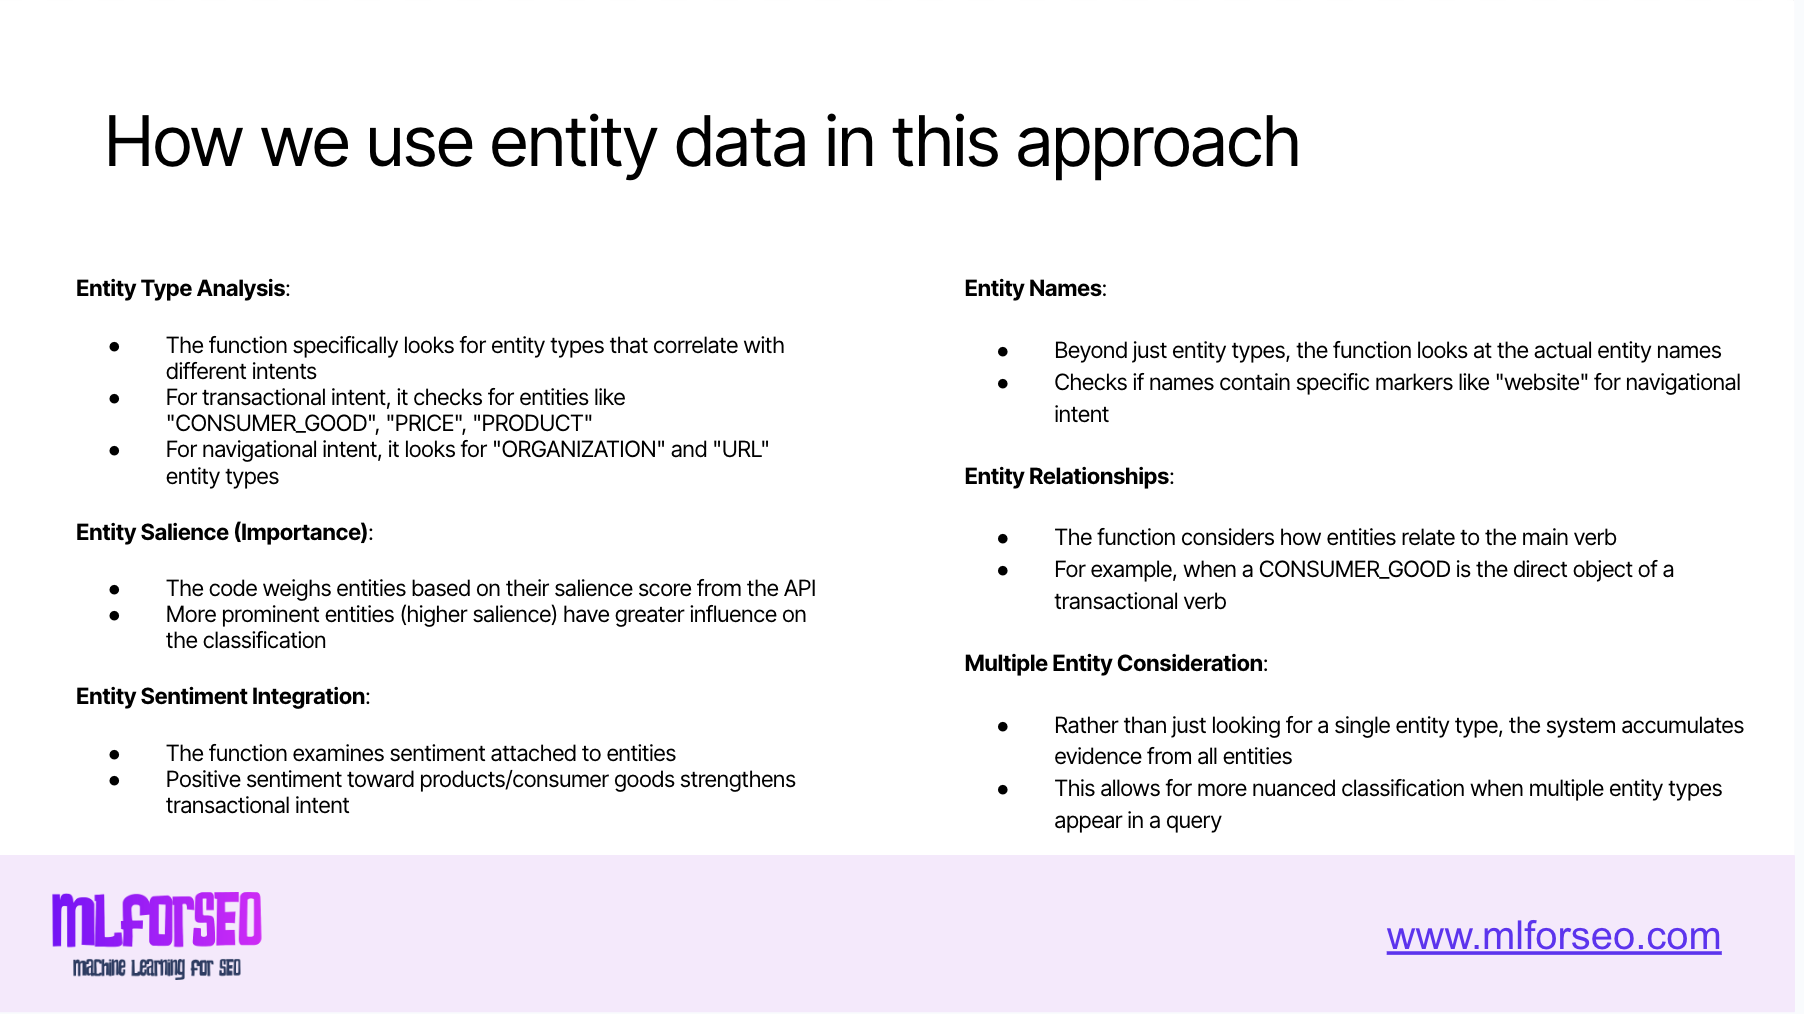


Finally, it returns one of the search intent labels., or a hybrid label.
## Additional Features:

* Automatic Dependency Management

* Results Visualization

* User Interface Improvements

  * Clear section headers and progress indicators
  *Preview of input and output data with display()
  *More intuitive user instructions
## Running the function:
The script uploads the CSV file (from Colab’s file uploader), processes each row (using only the Keyword column), builds an output DataFrame with the final semantic intent label, saves it to a CSV file, and triggers an automatic download. It also prints the first few rows with df.head(), and produces a visualization. **You need an API key from Google Cloud NLP API to run this function.**

This approach uses both semantic parsing with spaCy and entity extraction via Google Cloud NLP to produce a final search intent label for each query.

In [ ]:
import pandas as pd
import requests
import json
import time
import spacy
from google.colab import files
import re
from tqdm.notebook import tqdm
import matplotlib.pyplot as plt
import seaborn as sns

# Display setup message
print("Setting up Semantic Intent Classification Tool...")

# Check if spaCy model is installed, install if not
try:
    nlp = spacy.load("en_core_web_sm")
    print("✓ spaCy model loaded successfully")
except OSError:
    print("Installing spaCy model...")
    !python -m spacy download en_core_web_sm
    nlp = spacy.load("en_core_web_sm")
    print("✓ spaCy model installed and loaded")

#########################################
# 1. Configuration
#########################################
class Config:
    """Configuration settings for the script"""
    # API settings
    # Replace with your actual API key.
    API_KEY = None  # Will be set by user
    API_ENDPOINT = "https://language.googleapis.com/v1/documents:analyzeEntitySentiment"

    # Rate limiting
    MAX_CALLS_PER_MINUTE = 600
    TIME_WINDOW = 60  # seconds

    # Intent classification parameters
    HYBRID_INTENT_THRESHOLD = 2  # Maximum score difference to consider hybrid intent

    # Vocabulary lists for intent classification
    INTERROGATIVE_WORDS = {"how", "what", "why", "when", "who", "which", "where"}
    QUESTION_MARKERS = {"?", "explain", "guide", "tutorial", "help", "info", "information", "learn", "meaning"}

    TRANSACTIONAL_VERBS = {"buy", "purchase", "order", "shop", "get", "acquire", "book", "reserve",
                          "subscribe", "pay", "download", "checkout", "add"}
    TRANSACTIONAL_MARKERS = {"price", "cost", "cheap", "discount", "deal", "sale", "coupon", "shipping",
                           "delivery", "purchase", "cart", "checkout", "buy", "order"}

    NAVIGATIONAL_VERBS = {"go", "visit", "access", "login", "sign", "register", "navigate", "open", "find"}
    NAVIGATIONAL_MARKERS = {"website", "page", "site", "portal", "login", "official", "homepage", "web", "link"}

    COMMERCIAL_MARKERS = {"best", "top", "review", "compare", "vs", "versus", "comparison", "recommend",
                         "recommended", "rating", "alternative", "better", "difference", "pros", "cons"}
    LIST_INDICATORS = {"best", "top", "list"}

    TRANSACTIONAL_ENTITY_TYPES = {"CONSUMER_GOOD", "PRICE", "NUMBER", "WORK_OF_ART", "EVENT", "PRODUCT"}

#########################################
# 2. Google Cloud Natural Language API Call
#########################################
def analyze_entity_sentiment(content, api_key):
    """
    Calls the Google Cloud Natural Language API's entity sentiment analysis.

    Args:
        content (str): The text content to analyze
        api_key (str): Google Cloud API key

    Returns:
        dict: The API response containing entity sentiment analysis

    Raises:
        Exception: If API call fails or quota is exceeded
    """
    url = f"{Config.API_ENDPOINT}?key={api_key}"
    headers = {"Content-Type": "application/json"}
    payload = {
        "document": {
            "type": "PLAIN_TEXT",
            "content": content
        },
        "encodingType": "UTF8"
    }

    response = requests.post(url, headers=headers, data=json.dumps(payload))
    if response.status_code == 200:
        return response.json()
    elif response.status_code == 429:
        raise Exception("Quota limit exceeded: Too many requests in a short time.")
    else:
        error_msg = f"API call failed: {response.status_code}"
        try:
            error_details = response.json().get("error", {}).get("message", "")
            if error_details:
                error_msg += f" - {error_details}"
        except:
            error_msg += f" - {response.text}"
        raise Exception(error_msg)

#########################################
# 3. Semantic Parsing & Intent Classification
#########################################
def semantic_intent_classification(query, api_key):
    """
    Uses both Google Cloud NLP (for entity extraction) and spaCy (for semantic parsing)
    to determine the search intent of the query with improved semantic understanding.

    Args:
        query (str): The search query to classify
        api_key (str): Google Cloud API key

    Returns:
        str: The classified intent (Informational, Navigational, Transactional, Commercial)
             or a hybrid intent (e.g., "Commercial-Transactional")
    """
    # Clean and normalize the query
    query = query.strip()
    if not query:
        return "Undefined"

    # Initialize scores for each intent type
    intent_scores = {
        "Informational": 0,
        "Navigational": 0,
        "Transactional": 0,
        "Commercial": 0
    }

    # Debug information
    intent_evidence = {
        "Informational": [],
        "Navigational": [],
        "Transactional": [],
        "Commercial": []
    }

    # 1. Get entity data from Google NLP API
    try:
        entity_result = analyze_entity_sentiment(query, api_key)
        entities = entity_result.get("entities", [])
    except Exception as e:
        print(f"Error calling NLP API for query '{query}': {e}")
        entities = []

    # 2. Parse query with spaCy for semantic analysis
    doc = nlp(query)

    # 3. Check for informational signals
    if "?" in query:
        intent_scores["Informational"] += 3
        intent_evidence["Informational"].append("Contains '?'")

    if any(token.text.lower() in Config.INTERROGATIVE_WORDS for token in doc):
        intent_scores["Informational"] += 4
        intent_evidence["Informational"].append("Contains interrogative word")

    if any(token.text.lower() in Config.QUESTION_MARKERS for token in doc):
        intent_scores["Informational"] += 2
        intent_evidence["Informational"].append("Contains question marker")

    # 4. Extract main verb and objects for intent analysis
    main_verb = None
    direct_object = None

    for token in doc:
        if token.dep_ == "ROOT" and token.pos_ == "VERB":
            main_verb = token.lemma_.lower()
            # Look for direct object of the main verb
            for child in token.children:
                if child.dep_ in ("dobj", "pobj"):
                    direct_object = child.text.lower()
                    break

    # 5. Check for transactional signals
    if main_verb in Config.TRANSACTIONAL_VERBS:
        intent_scores["Transactional"] += 3
        intent_evidence["Transactional"].append(f"Transactional verb: {main_verb}")

    if any(token.text.lower() in Config.TRANSACTIONAL_MARKERS for token in doc):
        intent_scores["Transactional"] += 2
        markers = [t.text for t in doc if t.text.lower() in Config.TRANSACTIONAL_MARKERS]
        intent_evidence["Transactional"].append(f"Transactional markers: {', '.join(markers)}")

    # 6. Analyze entities for intent signals
    entity_evidence = []
    for entity in entities:
        entity_type = entity.get("type", "").upper()
        entity_name = entity.get("name", "").lower()
        entity_salience = entity.get("salience", 0)
        sentiment_score = entity.get("sentiment", {}).get("score", 0)

        # High salience entities are more important
        salience_factor = min(1.0, entity_salience * 2)

        # Check for transactional entities
        if entity_type in Config.TRANSACTIONAL_ENTITY_TYPES:
            score_addition = 2 * salience_factor
            intent_scores["Transactional"] += score_addition
            entity_evidence.append(f"{entity_type} ({entity_name}): +{score_addition:.1f} to Transactional")

        # If entity has positive sentiment and is a product, stronger transactional signal
        if entity_type in ("CONSUMER_GOOD", "PRODUCT") and sentiment_score > 0:
            intent_scores["Transactional"] += 1
            entity_evidence.append(f"Positive sentiment for {entity_type} ({entity_name}): +1 to Transactional")

        # Check for navigational entities
        if entity_type == "ORGANIZATION":
            intent_scores["Navigational"] += 2 * salience_factor
            entity_evidence.append(f"ORGANIZATION ({entity_name}): +{2 * salience_factor:.1f} to Navigational")

        # URLs or websites are strong navigational signals
        if entity_type == "URL" or "website" in entity_name:
            intent_scores["Navigational"] += 3 * salience_factor
            entity_evidence.append(f"URL/website ({entity_name}): +{3 * salience_factor:.1f} to Navigational")

    if entity_evidence:
        intent_evidence["Transactional"].extend(entity_evidence)

    # 7. Check for navigational signals
    if main_verb in Config.NAVIGATIONAL_VERBS:
        intent_scores["Navigational"] += 3
        intent_evidence["Navigational"].append(f"Navigational verb: {main_verb}")

    if any(token.text.lower() in Config.NAVIGATIONAL_MARKERS for token in doc):
        intent_scores["Navigational"] += 2
        markers = [t.text for t in doc if t.text.lower() in Config.NAVIGATIONAL_MARKERS]
        intent_evidence["Navigational"].append(f"Navigational markers: {', '.join(markers)}")

    # 8. Check for commercial signals (research before purchase)
    if any(token.text.lower() in Config.COMMERCIAL_MARKERS for token in doc):
        intent_scores["Commercial"] += 3
        markers = [t.text for t in doc if t.text.lower() in Config.COMMERCIAL_MARKERS]
        intent_evidence["Commercial"].append(f"Commercial markers: {', '.join(markers)}")

    # Look for comparison patterns (X vs Y, best X for Y)
    comparison_pattern = False
    for token in doc:
        if token.text.lower() in {"vs", "versus", "or", "vs.", "compared"}:
            comparison_pattern = True
            break

    if comparison_pattern:
        intent_scores["Commercial"] += 2
        intent_evidence["Commercial"].append("Comparison pattern detected")

    # Check for list intent (often commercial)
    if any(token.text.lower() in Config.LIST_INDICATORS for token in doc):
        intent_scores["Commercial"] += 2
        markers = [t.text for t in doc if t.text.lower() in Config.LIST_INDICATORS]
        intent_evidence["Commercial"].append(f"List indicators: {', '.join(markers)}")

    # 9. Consider specific patterns in the query structure
    # "How to" pattern strongly indicates informational
    if query.lower().startswith("how to"):
        intent_scores["Informational"] += 3
        intent_evidence["Informational"].append("Starts with 'how to'")

    # "Where to buy/get" pattern indicates transactional
    if query.lower().startswith("where to buy") or query.lower().startswith("where to get"):
        intent_scores["Transactional"] += 3
        intent_evidence["Transactional"].append("Starts with 'where to buy/get'")

    # "Best X for Y" pattern indicates commercial
    if "best" in query.lower() and " for " in query.lower():
        intent_scores["Commercial"] += 3
        intent_evidence["Commercial"].append("'Best X for Y' pattern")

    # 10. Determine final intent based on highest score
    max_intent = max(intent_scores.items(), key=lambda x: x[1])

    # If two intents have close scores, consider hybrid intent
    sorted_intents = sorted(intent_scores.items(), key=lambda x: x[1], reverse=True)
    if len(sorted_intents) >= 2:
        top_intent, top_score = sorted_intents[0]
        second_intent, second_score = sorted_intents[1]

        # If scores are close (within threshold), consider secondary intent
        if top_score > 0 and second_score > 0 and (top_score - second_score) <= Config.HYBRID_INTENT_THRESHOLD:
            return f"{top_intent}-{second_intent}"

    # If no clear signals detected, default to Informational
    if max_intent[1] == 0:
        return "Informational"

    return max_intent[0]

#########################################
# 4. Data Processing Functions
#########################################
def process_keywords(data, api_key, max_calls_per_minute=Config.MAX_CALLS_PER_MINUTE, show_progress=True):
    """
    Process keywords and classify their intent.

    Args:
        data (pd.DataFrame): DataFrame containing keywords to classify
        api_key (str): Google Cloud API key
        max_calls_per_minute (int): Maximum API calls per minute
        show_progress (bool): Whether to show a progress bar

    Returns:
        pd.DataFrame: DataFrame with classification results
    """
    # Check if 'Keyword' column exists
    if 'Keyword' not in data.columns:
        keyword_col = data.columns[0]
        print(f"'Keyword' column not found. Using '{keyword_col}' column instead.")
        data = data.rename(columns={keyword_col: 'Keyword'})

    # Prepare a list to hold the results
    results = []

    # Set up rate limiting
    api_calls = 0
    start_time = time.time()

    # Set up progress bar
    iterator = tqdm(data.iterrows(), total=len(data)) if show_progress else data.iterrows()

    for index, row in iterator:
        query = row["Keyword"]

        # Enforce rate limiting if needed
        api_calls += 1
        if api_calls >= max_calls_per_minute:
            elapsed_time = time.time() - start_time
            if elapsed_time < Config.TIME_WINDOW:
                sleep_time = Config.TIME_WINDOW - elapsed_time
                if show_progress:
                    tqdm.write(f"Rate limit reached. Sleeping for {sleep_time:.2f} seconds...")
                else:
                    print(f"Rate limit reached. Sleeping for {sleep_time:.2f} seconds...")
                time.sleep(sleep_time)
            api_calls = 0
            start_time = time.time()

        try:
            final_label = semantic_intent_classification(query, api_key)
            result = {
                "Keyword": query,
                "Semantic Intent Label": final_label
            }

            # Add any other columns from the original dataframe
            for col in row.index:
                if col != "Keyword" and col not in result:
                    result[col] = row[col]

            results.append(result)

        except Exception as e:
            if show_progress:
                tqdm.write(f"Error processing query '{query}': {e}")
            else:
                print(f"Error processing query '{query}': {e}")
            results.append({
                "Keyword": query,
                "Semantic Intent Label": "Error",
                "Error": str(e)
            })

    # Convert the results to a DataFrame
    output_df = pd.DataFrame(results)
    return output_df

#########################################
# 5. Visualization Functions
#########################################
def visualize_intent_distribution(df):
    """
    Create visualizations for intent distribution.

    Args:
        df (pd.DataFrame): DataFrame with classification results
    """
    intent_col = 'Semantic Intent Label'

    # Count the occurrences of each intent
    intent_counts = df[intent_col].value_counts()

    # Create a pie chart
    plt.figure(figsize=(10, 6))
    plt.subplot(1, 2, 1)
    intent_counts.plot.pie(autopct='%1.1f%%', startangle=90, colors=sns.color_palette("viridis", len(intent_counts)))
    plt.ylabel('')
    plt.title('Intent Distribution')

    # Create a bar chart
    plt.subplot(1, 2, 2)
    ax = intent_counts.plot.bar(color=sns.color_palette("viridis", len(intent_counts)))
    plt.title('Intent Counts')
    plt.ylabel('Count')
    plt.xlabel('Intent')

    # Add count labels to the bars
    for i, v in enumerate(intent_counts):
        ax.text(i, v + 0.1, str(v), ha='center')

    plt.tight_layout()
    plt.show()

    # If there are hybrid intents, show their breakdown
    hybrid_intents = df[df[intent_col].str.contains('-', na=False)]
    if not hybrid_intents.empty:
        print(f"\nFound {len(hybrid_intents)} hybrid intents:")
        print(hybrid_intents[intent_col].value_counts())

#########################################
# 6. Main Function
#########################################
def main():
    """Main function to run the script"""
    print("\n" + "="*50)
    print("Semantic Intent Classification Tool")
    print("="*50)

    # Get API key from user
    api_key = input("\nEnter your Google Cloud API key: ")
    if not api_key or api_key.lower() == "your_api_key":
        print("⚠️ Warning: No valid API key provided. Using demo mode with limited functionality.")
        api_key = None

    Config.API_KEY = api_key

    # Prompt the user to upload a CSV file
    print("\nPlease upload your CSV file (with a 'Keyword' column):")
    try:
        uploaded = files.upload()
        if not uploaded:
            raise Exception("No file uploaded")

        # Read the uploaded CSV file
        input_filename = list(uploaded.keys())[0]
        data = pd.read_csv(input_filename)

        print(f"\n✓ Successfully loaded file: {input_filename}")
        print(f"✓ Found {len(data)} keywords to process")

        # Show a preview of the data
        print("\nPreview of input data:")
        display(data.head())

        # Process the data
        print("\nProcessing keywords (this may take a while)...")
        output_df = process_keywords(data, api_key)

        # Display the results
        print("\n✓ Processing complete!")
        print("\nResults preview:")
        display(output_df.head())

        # Visualize the results
        print("\nIntent distribution:")
        visualize_intent_distribution(output_df)

        # Save the output to a CSV file
        output_filename = "semantic_intent_output.csv"
        output_df.to_csv(output_filename, index=False)

        # Download the output file
        print(f"\nDownloading results to {output_filename}...")
        files.download(output_filename)

        print("\n" + "="*50)
        print("✅ Process completed successfully!")
        print("="*50)

    except Exception as e:
        print(f"\n❌ Error: {str(e)}")
        print("\nPlease try again or check your input data/API key.")

# Run the script when executed directly
if __name__ == "__main__":
    main()
else:
    # Initialize for module usage
    print("Semantic Intent Classification module imported successfully")
